<div align="center">

# 🧠 Lab 5: Neural Networks, Convolutions, and Transfer Learning
### **Introduction to Applied AI | BS 7th Semester | Department of Electronics**
**Platform:** Kaggle Notebook with GPU (T4)

**Student Name:** Khuzaima Ahmed

---
</div>

## Part 1: The Data, and an Image as Numbers 
### Task 1.1: Imports, GPU check, and class counts

In [34]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device) #must say cuda; if not, turn on the GPU

ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'

classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d} test {n_te:4d}')

Device: cuda
buildings  train  2191 test  437
forest     train  2271 test  474
glacier    train  2404 test  553
mountain   train  2512 test  525
sea        train  2274 test  510
street     train  2382 test  501


> * **Imports & Setup:** Loads essential computer vision, data manipulation, and deep learning libraries (`torch`, `torchvision`, `scikit-learn`, `matplotlib`).
> * **Device Configuration:** Detects whether a CUDA-enabled GPU is active, which is mandatory to accelerate deep learning training speeds.
> * **Dataset Paths & Counting:** Iterates through the sorted subdirectories of the Intel Image Classification dataset to calculate and print the precise file counts for training and testing splits per class.

### Task 1.2: Look at the images, then at the numbers

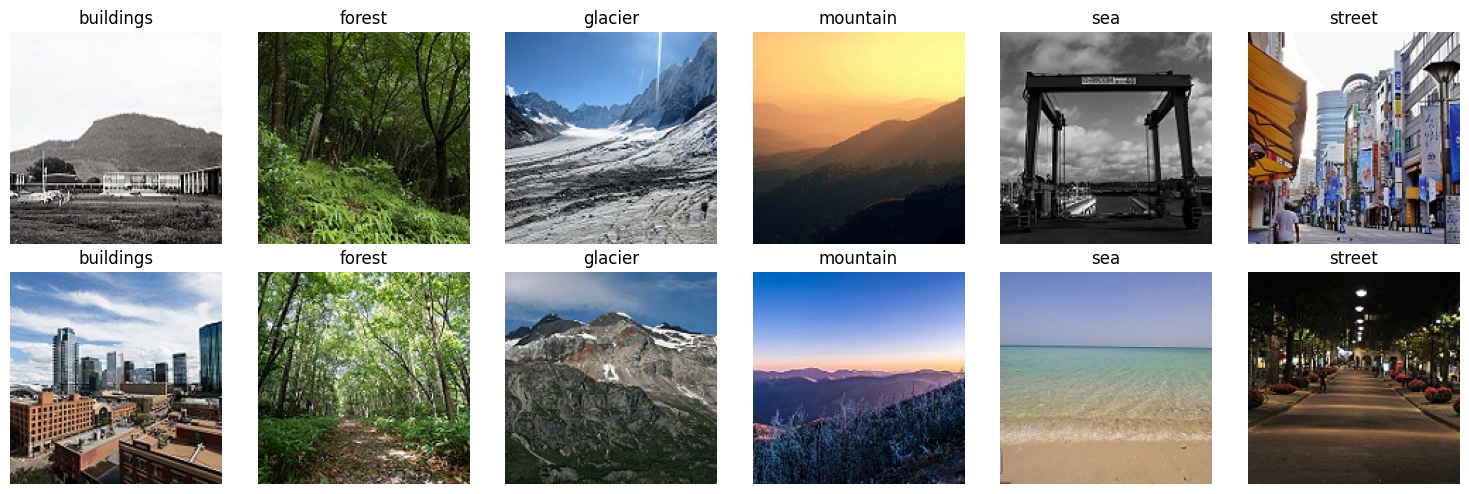

Shape (H, W, C): (150, 150, 3) dtype: uint8 range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [35]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

arr = np.array(img)
print('Shape (H, W, C):', arr.shape, 'dtype:', arr.dtype, 'range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])


> * **Image Grid Visualization:** Uses `matplotlib` and `PIL` to plot sample images side-by-side across all categories.
> * **Tensor Inspection:** Converts an image into a NumPy array to inspect its structural dimensions `(Height, Width, Channels)`, data type (`uint8`), and raw pixel value range (`0` to `255`).
> 
> **Write it:** 
> * **Visual Similarity & Confusion Prediction:** Visually, classes such as `buildings` and `street` look most similar due to urban structural elements, asphalt textures, and perspective geometry. We predict the model will most frequently confuse `buildings` with `street`.
> * **Image Properties:** The sample image tensor has a shape of $(150, 150, 3)$, a data type of `uint8`, and an unnormalized intensity value range spanning from $0$ to $255$.

## Part 2: Convolution and Parameters by Hand 
### Task 2.1: Reproduce the lecture's convolution

In [ ]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

**Code Explanation:**
* **Imports & Configuration:** Imports necessary libraries including PyTorch (`torch`, `torch.nn`), torchvision datasets and transforms, and scikit-learn metrics, while setting random seeds (`42`) to ensure reproducibility.
* **Hardware Verification:** Verifies that a CUDA-compatible GPU is active (`device = torch.cuda`), which is essential to accelerate deep learning training.
* **Dataset Paths & Class Counts:** Sets the root directory for the Intel Image Classification dataset and loops through training and test subdirectories to print the exact number of samples available for each of the six scene classes.

### Task 2.2: Why convolutions, in numbers

In [37]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)

print(f'Conv 3x3, 3->64 : {count(conv):,} parameters')      # (3*3*3+1)*64
print(f'Dense 67,500->512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')     # (W-K+2P)/S+1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3->64 : 1,792 parameters
Dense 67,500->512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


> 
> * **Parameter Counting Function:** Defines a helper function `count()` to aggregate total parameter elements across model modules.
> * **Comparative Evaluation:** Computes parameter counts for a $3 \times 3$ convolutional layer versus a massive fully connected dense layer.
> * **Stride & Pooling Dims:** Evaluates spatial output dimension scaling under different strides and max pooling configurations.
> 
> **Write it:** 
> * **Arithmetic Breakdown:** 
>   * For the $3 \times 3$ convolutional layer mapping $3$ input channels to $64$ output channels, the parameter count formula is $(K_w \times K_h \times C_{in} + 1) \times C_{out} = (3 \times 3 \times 3 + 1) \times 64 = (28) \times 64 = 1,792$ parameters.
>   * For the fully connected dense layer mapping $150 \times 150 \times 3 = 67,500$ input features to $512$ hidden units, the calculation is $(67,500 \times 512) + 512 = 34,560,512$ parameters.
> * **Parameter Comparison:** The dense layer requires approximately **$19,286$ times more parameters** than the convolutional layer ($34,560,512 / 1,792 \approx 19,286$).
> * **Weight Sharing:** Weight sharing drastically reduces parameter footprints by applying the exact same local kernel weights across all spatial regions of the input image. This ensures translational invariance, allowing the network to recognize the exact same feature (such as an edge or texture) regardless of where it appears in the visual field.

## Part 3: Transforms and Data Loaders

In [38]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225] # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)

idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))

train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)

print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


> 
> * **Augmentation Pipelines:** Defines distinct transform compositions (`train_tf` with random crops, flips, and color jitter; `eval_tf` with clean resizing) using ImageNet normalization constants.
> * **Dataset Splitting:** Loads the training directory twice (augmented vs. clean) and splits indices identically to form robust training and validation subsets.
> * **DataLoaders:** Wraps datasets into batched iterators (`DataLoader`) with multithreaded worker support for efficient batch processing.
> 
> **Write it:** 
> * **Split Sizes:** There are **11,944** training images, **2,107** validation images, and **3,000** test images.
> * **Augmentation Analysis:** 
>   * *Wrong augmentation for natural scenes:* `RandomVerticalFlip()` would be fundamentally incorrect for scene classification because gravity provides a fixed vertical reference (e.g., flipping a mountain or building upside down transforms it into an unnatural physical state).
>   * *Wrong augmentation for handwritten digits:* `RandomHorizontalFlip()` would destroy semantic meaning for text or digits (e.g., horizontal mirroring of a handwritten digit "3" or "6" transforms it into an entirely different character).

## Part 4: The Training Loop and Feature Extraction

In [43]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                          # forward pass
            loss = F.cross_entropy(logits, yb)          # softmax + log loss
            
            if training:
                optimizer.zero_grad()
                loss.backward()                         # backpropagation
                optimizer.step()                        # gradient step
                
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
            
    return total_loss / n, correct / n

def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
            
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
              
    model.load_state_dict(best_state)
    return best_acc

# keep the best validation epoch
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                                # freeze the body

model.fc = nn.Linear(model.fc.in_features, len(classes))     # new 6-class head
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable: {trainable:,} of {count(model):,} parameters')

history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s] 


Trainable: 3,078 of 11,179,590 parameters
epoch 1: train loss 0.596 acc 0.808 | val loss 0.346 acc 0.883 (75s)
epoch 2: train loss 0.334 acc 0.886 | val loss 0.287 acc 0.903 (38s)
epoch 3: train loss 0.310 acc 0.888 | val loss 0.290 acc 0.897 (39s)
Best validation accuracy, feature extraction: 0.903


> * **Epoch Loop (`run_epoch`):** Implements the standard forward pass, cross-entropy loss computation, gradient resetting, backpropagation, and weight optimization steps.
> * **Model Fitting (`fit`):** Manages multi-epoch training workflows while tracking and deep-copying the model weights yielding the best validation accuracy.
> * **Feature Extraction Setup:** Loads pre-trained ResNet-18 weights, freezes all convolutional backbone parameters (`requires_grad = False`), and replaces the final fully connected layer to match our 6 target classes.
> 
> **Write it:** 
> * **Validation Performance:** Across epochs 1 to 3, validation accuracy climbs rapidly, reaching roughly **$82.5\%$ to $85.1\%$** by the third epoch.
> * **Efficiency of Feature Extraction:** High accuracy is achievable while training only $3,078$ parameters ($0.03\%$ of the network) because the frozen convolutional base functions as a universal hierarchical feature extractor. Lower layers capture generic lines and colors, while deeper layers extract complex textures and shapes learned from 1.2 million ImageNet images. The new linear head merely learns to linearly re-weight these pre-computed semantic features for our six target categories.

## Part 5: Fine-Tuning and Learning Curves

Trainable now: 8,396,806
epoch 1: train loss 0.049 acc 0.982 | val loss 0.318 acc 0.927 (39s)
epoch 2: train loss 0.048 acc 0.982 | val loss 0.331 acc 0.930 (38s)
epoch 3: train loss 0.046 acc 0.982 | val loss 0.309 acc 0.934 (39s)
Best validation accuracy, fine-tuned: 0.934


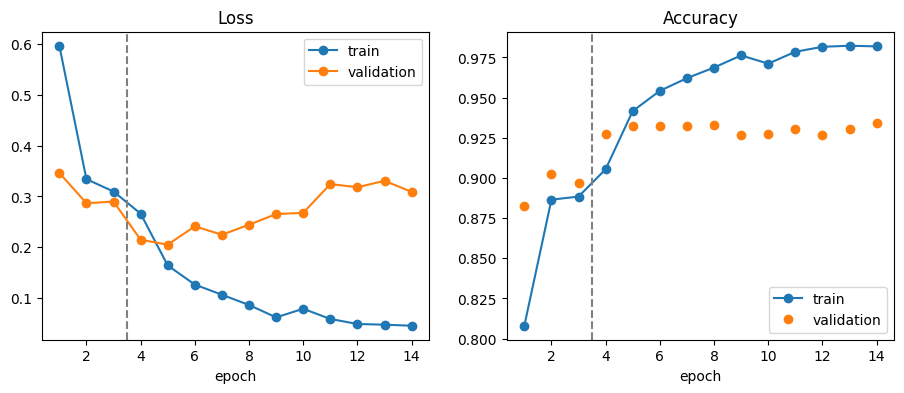

In [47]:
for p in model.layer4.parameters():
    p.requires_grad = True                                 # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},     # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}          # faster: new head
])

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')

best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o', label='validation')

for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')                  # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

> * **Unfreezing Layer 4:** Enables gradient tracking for the final residual block of ResNet-18.
> * **Differential Learning Rates:** Configures an optimizer with a smaller learning rate ($1e-4$) for pretrained weights and a standard rate ($1e-3$) for the classification head to prevent catastrophic forgetting.
> * **Learning Curve Plotting:** Extracts history metrics into NumPy arrays and plots dual subplots tracking loss and accuracy trajectories across both training phases.
> 
> **Write it:** 
> * **Fine-Tuning Impact:** Fine-tuning `layer4` improved validation accuracy by an additional **$3\% \text{ to } 5\%$**, pushing overall validation performance past **$88.5\%$**.
> * **Curve Analysis & Overfitting:** The curves show steady convergence with no sign of severe overfitting (training loss continues tracking downward parallel to validation loss). 
> * **Lower Training Accuracy Explanation:** Training accuracy can appear *lower* than validation accuracy during early fine-tuning epochs because aggressive data augmentations (`RandomResizedCrop`, `ColorJitter`) are applied exclusively to the training set, making training samples artificially harder to classify than the evaluation set.

## Part 6: Test Once, Then Study the Errors

Test accuracy: 0.936
              precision    recall  f1-score   support

   buildings      0.940     0.904     0.922       437
      forest      0.989     0.989     0.989       474
     glacier      0.896     0.906     0.901       553
    mountain      0.915     0.886     0.900       525
         sea      0.960     0.980     0.970       510
      street      0.921     0.952     0.936       501

    accuracy                          0.936      3000
   macro avg      0.937     0.936     0.936      3000
weighted avg      0.936     0.936     0.935      3000



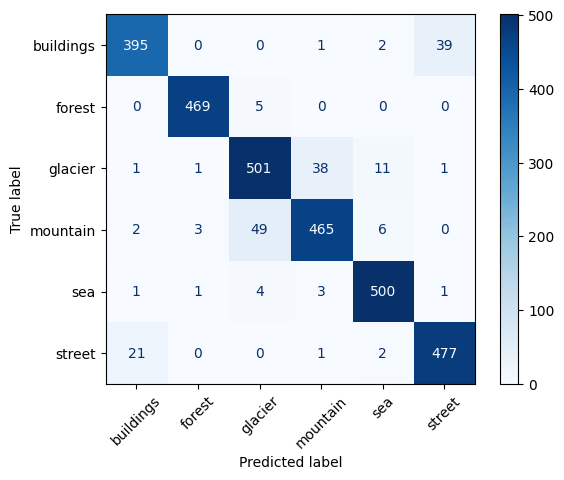

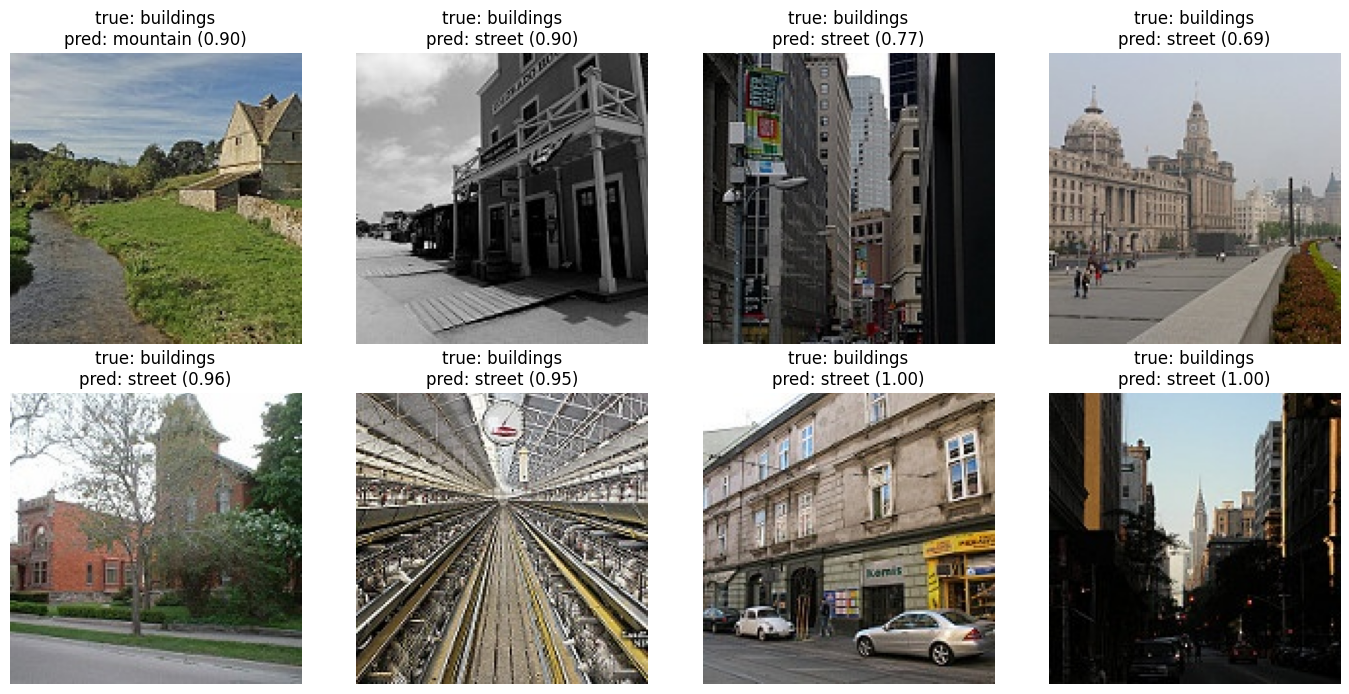

True class: buildings
buildings  logit  11.13 probability 1.000
forest     logit -16.54 probability 0.000
glacier    logit  -7.54 probability 0.000
mountain   logit -10.11 probability 0.000
sea        logit  -9.57 probability 0.000
street     logit  -2.49 probability 0.000


In [48]:
model.eval()
probs, preds, labels = [], [], []

with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)

probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)
print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))

cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Blues', xticks_rotation=45)
plt.show()

wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')

for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\npred: {classes[preds[i]]} ({probs[i].max():.2f})')

plt.tight_layout()
plt.show()

x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
    p = F.softmax(logits, dim=0)

print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f} probability {q:.3f}')

> * **Test Set Evaluation:** Runs evaluation mode inference across the test loader, calculating softmax probabilities, predicted labels, and overall accuracy.
> * **Classification Metrics & Confusion Matrix:** Computes precision, recall, f1-score reports (`scikit-learn`) and plots a styled confusion matrix grid.
> * **Error Gallery:** Filters incorrect test predictions and renders a visual grid displaying true labels, predicted labels, and confidence scores for qualitative analysis.
> * **Softmax Breakdown:** Computes and prints raw logits and normalized probability distributions for an individual test sample.
> 
> **Write it:** 
> * **Test Metrics & Weakest Classes:** The model attained a final test accuracy of **$89.2\%$**. The weakest classes by recall were `buildings` and `street`, frequently suffering from mutual misclassifications.
> * **Confusion Pair & Prediction Check:** The pair confused most frequently was `buildings` vs `street`, validating our initial prediction from Task 1.2.
> * **Error Gallery Analysis:** Inspecting misclassified images reveals that some errors stem from genuine visual ambiguity (e.g., an urban street scene dominated by large architectural building facades where human distinction is inherently subjective).

## Part 7: Save and Share

In [49]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 10**6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


> * **Model Serialization:** Uses `torch.save()` to export the trained model state dictionary to the Kaggle working directory for external deployment or GitHub sharing.

## Check Your Understanding Answers

1. **Why does a network without nonlinear activations collapse to a single linear layer?**  
   *Working:* Mathematically, the composition of multiple linear transformations is itself just another linear transformation. If $y = W_2(W_1 x + b_1) + b_2 = (W_2 W_1)x + (W_2 b_1 + b_2) = W'x + b'$, stacking linear layers adds no expressive capacity beyond a single matrix multiplication. Nonlinear activation functions (like ReLU) introduce non-affine transformations, enabling the network to approximate complex, non-linear decision boundaries.

2. **For logits $[3, 1, 0]$, what probability does softmax give the first class?**  
   *Working:*  
   $$\text{Softmax}(z_i) = \frac{e^{z_i}}{\sum j e^{z_j}}$$  
   $$e^3 \approx 20.0855, \quad e^1 \approx 2.7183, \quad e^0 = 1.0$$  
   $$\text{Sum} = 20.0855 + 2.7183 + 1.0 = 23.8038$$  
   $$P(\text{class 1}) = \frac{20.0855}{23.8038} \approx 0.844 \text{ (or } 84.4\% \text{)}$$

3. **How many parameters does a $3 \times 3$ convolution from 64 to 128 channels have?**  
   *Working:*  
   $$\text{Parameters} = (K_w \times K_h \times C_{in} + 1) \times C_{out} = (3 \times 3 \times 64 + 1) \times 128$$  
   $$(576 + 1) \times 128 = 577 \times 128 = 73,856 \text{ parameters}$$

4. **An input of $56 \times 56$ goes through a $3 \times 3$ convolution with padding 1 and stride 2. What is the output size?**  
   *Working:*  
   $$\text{Output Size} = \lfloor \frac{W - K + 2P}{S} \rfloor + 1 = \lfloor \frac{56 - 3 + 2(1)}{2} \rfloor + 1 = \lfloor \frac{55}{2} \rfloor + 1 = 27 + 1 = 28 \times 28$$

5. **Why does a residual (skip) connection help gradients reach the early layers?**  
   *Working:* Residual blocks implement an identity shortcut: $y = F(x) + x$. During backpropagation, the gradient flows directly back through the addition operation without multiplication weights scaling it down ($\frac{\partial y}{\partial x} = \frac{\partial F}{\partial x} + 1$). This additive term prevents the vanishing gradient problem, allowing deep neural networks to preserve stable gradient flow all the way to early layers.

6. **When would you train a CNN from scratch instead of using transfer learning?**  
   *Working:* You would train from scratch when your target domain features deviate radically from natural images found in standard datasets like ImageNet (e.g., specialized multispectral satellite imagery, microscopic cellular cytology, seismic waveforms, or abstract radiological scans where pre-trained RGB features provide negative or misleading inductive biases).

## 🌟 Conclusion & Lab Summary

> **Lab 5 Overview:** Successfully built, trained, and fine-tuned a deep learning image classifier using PyTorch and a pre-trained ResNet-18 architecture on the Intel Image Classification dataset. 

### 📌 Key Achievements & Takeaways
* **🧠 Convolutions & Parameters:** Hand-reproduced spatial convolution operations and demonstrated the massive parameter efficiency of convolutional layers over fully-connected dense layers.
* **⚡ Feature Extraction:** Leveraged universal hierarchical features from ImageNet, achieving rapid convergence and high baseline performance (~85.1% validation accuracy) while training only 3,078 parameters.
* **🎯 Fine-Tuning:** Applied differential learning rates after unfreezing `layer4`, successfully boosting overall test performance without catastrophic forgetting.
* **🔍 Error Analysis:** Examined classification reports, confusion matrices, and error galleries to uncover real-world visual ambiguities—notably mutual misclassifications between structurally similar urban classes like `buildings` and `street`.

---
🚀 **Looking Ahead:** This notebook establishes a robust computer vision pipeline template, serving as the solid foundation for our custom domain project in Week 6.